# Fine-Tune Metric Depth For Robot Geometry
**SOLUTION NOTEBOOK · ArtificialGate · Dr. Barak Or**

**Foundation of Physical AI · Physical AI Essentials, Lesson 2**

**Estimated participant work: 60 minutes.** Completed code and reference outputs. Task IDs and estimated times match the Exercise notebook.
Times include reading, coding, reruns, and interpretation; download speed can vary.

**Skills you will practise:** Adapt metric depth; validate camera/frame contracts; turn accepted targets into bounded Cartesian actions.

**Before you start:** Read the matching book lesson; know NumPy arrays and PyTorch tensors/gradients.

## Your 60-Minute Task Plan
| Task | Estimated time |
|---|---:|
| PAI2-T01 · Set Up The Runtime | 4 min |
| PAI2-T02 · Load And Inspect RGB-D | 6 min |
| PAI2-T03 · Select Parameters And Define Loss | 7 min |
| PAI2-T04 · Cache Frozen Image Features | 2 min |
| PAI2-T05 · Run Two Fine-Tunes | 9 min |
| PAI2-T06 · Evaluate The Held-Out Scene | 4 min |
| PAI2-T07 · Complete And Validate Geometry | 9 min |
| PAI2-T08 · Diagnose Calibration Changes | 6 min |
| PAI2-T09 · Inspect The 3D Reconstruction | 2 min |
| PAI2-T10 · Convert A Target Into An Action | 7 min |
| PAI2-T11 · Save And Explain | 4 min |
| **Total** | **60 min** |

### Task PAI2-T01 — Set Up The Runtime · 4 min
**Do:** Run setup using CPU; GPU is optional.  
**Produce:** A device message and private dependency paths.  
**Check:** No global PyTorch/NumPy package replacement.

In [1]:
#@title Setup
# Private notebook dependencies: never replace Colab's torch/numpy/sympy or global HF packages.
import importlib.util, importlib.metadata, os, subprocess, sys
from pathlib import Path
PRIVATE_DEPS = Path(".artificialgate_lab2_deps_v2").resolve()
PRIVATE_DEPS.mkdir(exist_ok=True)
sys.path.insert(0, str(PRIVATE_DEPS))
importlib.invalidate_caches()
PINNED = {"transformers": "4.57.1", "huggingface_hub": "0.35.3",
          "tokenizers": "0.22.1", "safetensors": "0.6.2"}
for module_name, expected in PINNED.items():
    loaded = sys.modules.get(module_name)
    if loaded is not None and getattr(loaded, "__version__", None) != expected:
        raise RuntimeError(f"A different {module_name} is already loaded. "
                           "Restart this notebook session, then run this setup cell first.")
private_specs = []
for package, expected in PINNED.items():
    try:
        installed = importlib.metadata.version(package)
    except importlib.metadata.PackageNotFoundError:
        installed = None
    if installed != expected:
        private_specs.append(package.replace("_", "-") + "==" + expected)
# The tiny support dependencies are installed privately only when unavailable.
support = {"h5py": "h5py==3.13.0", "requests": "requests==2.32.5",
           "urllib3": "urllib3==2.5.0", "charset_normalizer": "charset-normalizer==3.4.4",
           "idna": "idna==3.11", "certifi": "certifi==2025.10.5",
           "filelock": "filelock==3.20.0", "packaging": "packaging==25.0",
           "yaml": "PyYAML==6.0.3", "regex": "regex==2025.9.18",
           "tqdm": "tqdm==4.67.1", "fsspec": "fsspec==2025.9.0"}
for module_name, specification in support.items():
    if importlib.util.find_spec(module_name) is None:
        private_specs.append(specification)
if private_specs:
    subprocess.check_call([sys.executable, "-m", "pip", "-q", "install", "--no-deps",
                           "--upgrade", "--target", str(PRIVATE_DEPS), *private_specs])
importlib.invalidate_caches()
for core in ("torch", "numpy", "matplotlib", "PIL"):
    if importlib.util.find_spec(core) is None:
        raise RuntimeError("Use a standard Google Colab Python runtime; missing " + core)
# This exercise uses PyTorch + PIL only. Pinned Transformers must not import unused
# optional audio/torchvision backends from an unrelated Colab preinstallation.
os.environ["USE_TORCH"], os.environ["USE_TF"] = "1", "0"
import transformers
from transformers.utils import import_utils as _transformers_imports
_transformers_imports._librosa_available = False
_transformers_imports._torchvision_available = False

import copy, hashlib, io, json, re, tarfile, time, urllib.request
import h5py
import numpy as np
import torch
from torch import nn
import torch.nn.functional as F
import matplotlib.pyplot as plt
from PIL import Image
from transformers import AutoModelForDepthEstimation
from IPython.display import display
for module_name, expected in PINNED.items():
    actual = getattr(importlib.import_module(module_name), "__version__", None)
    if actual != expected:
        raise RuntimeError(f"{module_name} is already loaded as {actual}. "
                           "In Colab choose Runtime > Restart session, then Run all.")

SEED = 17
torch.manual_seed(SEED)
np.random.seed(SEED)
torch.set_num_threads(min(4, max(1, __import__("os").cpu_count() or 1)))
DEVICE = torch.device("cuda" if torch.cuda.is_available() else "cpu")
OUT = Path("artificialgate_lab2_results")
OUT.mkdir(exist_ok=True)
CACHE = Path("artificialgate_lab2_cache")
CACHE.mkdir(exist_ok=True)
BLUE, NAVY, CYAN, SILVER = "#1847FF", "#091637", "#14B9DC", "#93A4BB"
plt.rcParams.update({"axes.spines.top": False, "axes.spines.right": False,
                     "axes.prop_cycle": plt.cycler(color=[BLUE, CYAN, NAVY, SILVER]),
                     "figure.dpi": 110, "font.size": 10})
def TODO(message):
    raise NotImplementedError("Complete " + message + ", then rerun this cell.")
print("Device:", DEVICE, "| Trainable model: pretrained metric-depth head")


Device: cpu | Trainable model: pretrained metric-depth head


### Task PAI2-T02 — Load And Inspect RGB-D · 6 min
**Do:** Run loader and inspection; distinguish measured depth from a model estimate.  
**Produce:** 36 real RGB-D frames.  
**Check:** Training, validation, and test scenes are disjoint.

In [2]:
#@title Provided code — run this cell
DATA_REV = "50579a0b591445f91bf7269b28611ad1cc6a05d2"
DATA_BASE = f"https://huggingface.co/datasets/sayakpaul/nyu_depth_v2/resolve/{DATA_REV}/data/"
SCENE_PLAN = [
    ("train-000000.tar", "basement_0001a", "train"),
    ("train-000001.tar", "bedroom_0017", "train"),
    ("train-000002.tar", "bedroom_0062", "train"),
    ("train-000003.tar", "bedroom_0125b", "train"),
    ("train-000004.tar", "dining_room_0007", "validation"),
    ("train-000005.tar", "dining_room_0034", "test"),
]
FRAMES_PER_SCENE = 6
HEIGHT, WIDTH = 168, 224  # Both divisible by the model's 14-pixel patch size.

def canonical_scene(name):
    return re.match(r"(.+_\d+)", name).group(1)

def stream_scene(shard, scene, split):
    scene_cache = CACHE / "nyu_depth_v2" / DATA_REV / scene
    scene_cache.mkdir(parents=True, exist_ok=True)
    local = sorted(scene_cache.glob("*.h5"))[:FRAMES_PER_SCENE]
    if len(local) < FRAMES_PER_SCENE:
        request = urllib.request.Request(DATA_BASE + shard, headers={"User-Agent": "ArtificialGate-Colab/1"})
        with urllib.request.urlopen(request, timeout=90) as response:
            with tarfile.open(fileobj=response, mode="r|") as archive:
                count = 0
                for member in archive:
                    if not member.isfile() or not member.name.endswith(".h5"):
                        continue
                    parts = member.name.split("/")
                    if len(parts) != 3 or parts[1] != scene:
                        raise RuntimeError("Pinned dataset layout changed: " + member.name)
                    payload = archive.extractfile(member).read()
                    if len(payload) > 3_000_000:
                        raise RuntimeError("Unexpected HDF5 sample size")
                    (scene_cache / parts[-1]).write_bytes(payload)
                    count += 1
                    if count == FRAMES_PER_SCENE:
                        break
                if count != FRAMES_PER_SCENE:
                    raise RuntimeError("Incomplete scene prefix; retry the download cell.")
        local = sorted(scene_cache.glob("*.h5"))[:FRAMES_PER_SCENE]
    result = []
    for path in local:
        raw = path.read_bytes()
        with h5py.File(io.BytesIO(raw), "r") as handle:
            rgb, depth = np.asarray(handle["rgb"]), np.asarray(handle["depth"], dtype=np.float32)
        if rgb.shape[0] == 3:
            rgb = np.moveaxis(rgb, 0, -1)
        assert rgb.shape[:2] == depth.shape == (480, 640)
        assert rgb.dtype == np.uint8 and 0 < np.nanmedian(depth) < 20
        result.append({"rgb": rgb, "depth": depth, "scene": canonical_scene(scene),
                       "split": split, "source": f"{shard}:train/{scene}/{path.name}",
                       "sha256": hashlib.sha256(raw).hexdigest()})
    return result

records = []
download_started = time.perf_counter()
for shard, scene, split in SCENE_PLAN:
    records.extend(stream_scene(shard, scene, split))
    print(f"{split:10s} {scene:20s} {FRAMES_PER_SCENE} frames")
scene_sets = {s: {r["scene"] for r in records if r["split"] == s}
              for s in ("train", "validation", "test")}
assert not (scene_sets["train"] & scene_sets["validation"])
assert not (scene_sets["train"] & scene_sets["test"])
assert not (scene_sets["validation"] & scene_sets["test"])
manifest = [{k: v for k, v in r.items() if k not in ("rgb", "depth")} for r in records]
(OUT / "data_manifest.json").write_text(json.dumps({"revision": DATA_REV, "samples": manifest}, indent=2))
print(f"Loaded {len(records)} recorded frames in {time.perf_counter()-download_started:.1f}s")


train      basement_0001a       6 frames
train      bedroom_0017         6 frames
train      bedroom_0062         6 frames
train      bedroom_0125b        6 frames
validation dining_room_0007     6 frames
test       dining_room_0034     6 frames
Loaded 36 recorded frames in 1.3s


RGB: (36, 3, 168, 224) | Metric labels: (36, 168, 224)


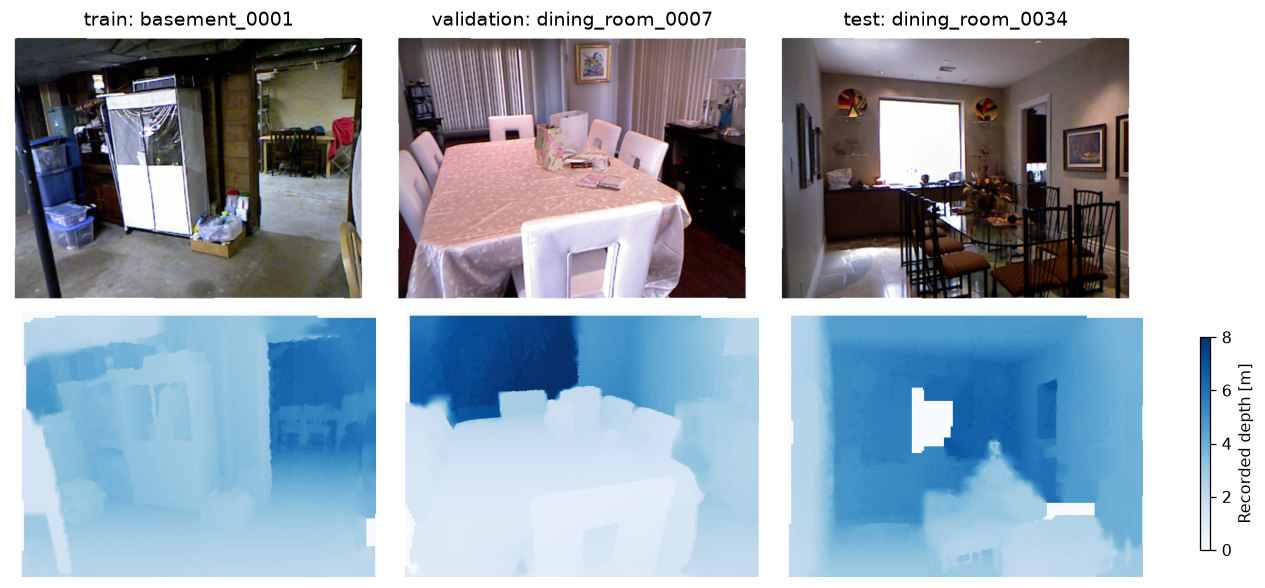

In [3]:
# Inspect real samples and resize depth without interpolating across missing measurements.
fig, axes = plt.subplots(2, 3, figsize=(11, 5), constrained_layout=True)
for col, split in enumerate(("train", "validation", "test")):
    row = next(r for r in records if r["split"] == split)
    axes[0, col].imshow(row["rgb"])
    axes[0, col].set_title(f"{split}: {row['scene']}")
    image = axes[1, col].imshow(row["depth"], cmap="Blues", vmin=0, vmax=8)
    for ax in axes[:, col]: ax.axis("off")
fig.colorbar(image, ax=axes[1].tolist(), label="Recorded depth [m]", shrink=.8)
plt.show()

rgb_tensor = torch.stack([torch.from_numpy(r["rgb"].copy()).permute(2, 0, 1).float()/255 for r in records])
rgb_tensor = F.interpolate(rgb_tensor, size=(HEIGHT, WIDTH), mode="bilinear", align_corners=False)
target = torch.stack([torch.from_numpy(r["depth"].copy()) for r in records])[:, None]
target = F.interpolate(target, size=(HEIGHT, WIDTH), mode="nearest")[:, 0]
valid = torch.isfinite(target) & (target > 0.1) & (target < 10.0)
mean = torch.tensor([0.485, 0.456, 0.406])[None, :, None, None]
std = torch.tensor([0.229, 0.224, 0.225])[None, :, None, None]
pixels = (rgb_tensor - mean) / std
indices = {s: torch.tensor([i for i, r in enumerate(records) if r["split"] == s])
           for s in ("train", "validation", "test")}
assert valid[indices["train"]].any() and target[valid].isfinite().all()
print("RGB:", tuple(pixels.shape), "| Metric labels:", tuple(target.shape))


### Task PAI2-T03 — Select Parameters And Define Loss · 7 min
**Do:** Complete A/B: train only the head and mask invalid depth labels.  
**Produce:** Trainable head and masked loss.  
**Check:** Encoder frozen; invalid pixels have zero gradient.

In [4]:
MODEL_ID = "depth-anything/Depth-Anything-V2-Metric-Indoor-Small-hf"
MODEL_REV = "8078d68a9c75a972131914f6afd0c1723be0da7f"
model = AutoModelForDepthEstimation.from_pretrained(MODEL_ID, revision=MODEL_REV).to(DEVICE).eval()
assert model.config.depth_estimation_type == "metric" and model.config.max_depth == 20
for name, parameter in model.named_parameters():
    trainable = name.startswith("head.")  # TODO A
    assert isinstance(trainable, bool), "Return a Boolean parameter-selection mask."
    parameter.requires_grad_(trainable)

def masked_depth_loss(prediction, target, valid):
    assert valid.any(), "No valid depth labels in this batch."
    return (prediction[valid] - target[valid]).abs().mean()  # TODO B

example_prediction = torch.tensor([1.0, 3.0, 100.0], requires_grad=True)
example_target = torch.tensor([2.0, 1.0, 0.0])
example_mask = torch.tensor([True, True, False])
example_loss = masked_depth_loss(example_prediction, example_target, example_mask)
assert torch.isclose(example_loss, torch.tensor(1.5)), "Check masking and averaging."
example_loss.backward()
assert example_prediction.grad[-1] == 0, "Invalid pixels must not contribute gradients."
trainable_names = [n for n, p in model.named_parameters() if p.requires_grad]
assert trainable_names and all(n.startswith("head.") for n in trainable_names)
assert all(not p.requires_grad for p in model.backbone.parameters())
print("Trainable parameters:", sum(p.numel() for p in model.parameters() if p.requires_grad))


Trainable parameters: 27745


### Task PAI2-T04 — Cache Frozen Image Features · 2 min
**Do:** Run feature extraction once.  
**Produce:** Reusable frozen features.  
**Check:** Cached and full-model predictions agree.

In [5]:
# Frozen image features are computed once; the pretrained head still trains normally.
patch_h, patch_w = HEIGHT // model.config.patch_size, WIDTH // model.config.patch_size
feature_key = hashlib.sha256(json.dumps({
    "model": MODEL_REV, "dataset": DATA_REV, "samples": manifest,
    "resolution_hw": [HEIGHT, WIDTH],
    "preprocessing": "rgb01_bilinear_align_corners_false_imagenet_mean_std_v1",
}, sort_keys=True).encode()).hexdigest()[:20]
feature_cache_path = CACHE / f"metric_features_{feature_key}.pt"
if feature_cache_path.exists():
    features = torch.load(feature_cache_path, map_location="cpu", weights_only=True)
else:
    pieces = []
    started = time.perf_counter()
    for start in range(0, len(pixels), 2):
        with torch.no_grad():
            backbone_out = model.backbone.forward_with_filtered_kwargs(pixels[start:start+2].to(DEVICE))
            neck_out = model.neck(backbone_out.feature_maps, patch_h, patch_w)
            pieces.append(neck_out[model.head.head_in_index].detach().cpu())
        print(f"Encoded {min(start+2, len(pixels))}/{len(pixels)} images", end="\r")
    features = torch.cat(pieces)
    torch.save(features, feature_cache_path)
    print(f"\nFrozen feature extraction: {time.perf_counter()-started:.1f}s")
assert features.shape[0] == len(records) and torch.isfinite(features).all()
initial_head = copy.deepcopy(model.head.state_dict())
def head_prediction(head, ix):
    return head([features[ix].to(DEVICE)], patch_h, patch_w)
@torch.no_grad()
def evaluate_head(head, ix):
    head.eval()
    values = []
    for j in ix.split(2):
        values.append(masked_depth_loss(head_prediction(head, j), target[j].to(DEVICE), valid[j].to(DEVICE)).item())
    return float(np.mean(values))
with torch.no_grad():
    # Ensure feature caching reproduces the full pretrained model.
    direct = model(pixel_values=pixels[:1].to(DEVICE)).predicted_depth
    cached = head_prediction(model.head, torch.tensor([0]))
    assert torch.allclose(direct, cached, atol=1e-4, rtol=1e-4)
print("Feature cache:", tuple(features.shape), "| Cached and full inference agree.")


Feature cache: (36, 64, 96, 128) | Cached and full inference agree.


### Task PAI2-T05 — Run Two Fine-Tunes · 9 min
**Do:** Compare the two rates from identical weights, data, and step budgets.  
**Produce:** Train/validation curves.  
**Check:** Head weights change; validation selects the checkpoint.

lr=1e-05: best validation MAE=0.900 m; updated weights L1=9.664; 12.8s
lr=0.0003: best validation MAE=1.002 m; updated weights L1=76.532; 17.1s


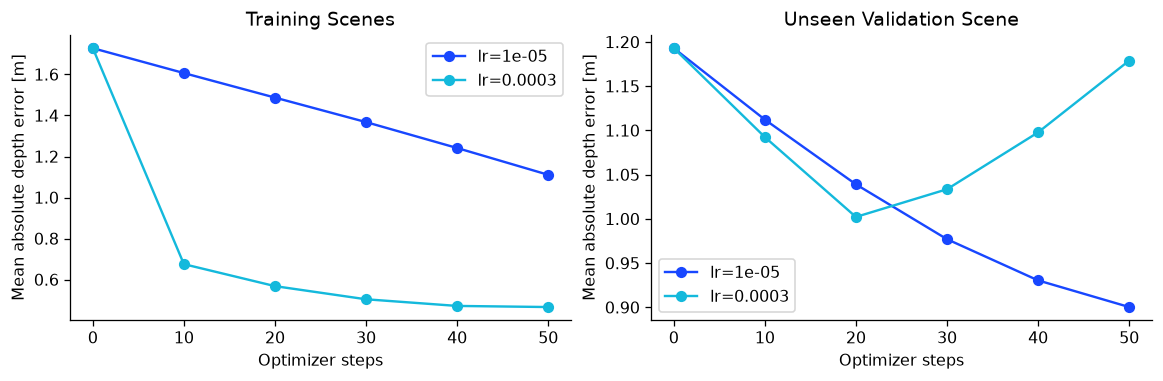

In [6]:
LEARNING_RATES = [1e-5, 3e-4]  # Experiment: change one rate, keep everything else fixed.
TRAIN_STEPS = 50
BATCH_SIZE = 2
CHECK_EVERY = 10
runs = []
train_ix, val_ix = indices["train"], indices["validation"]
for lr in LEARNING_RATES:
    torch.manual_seed(SEED)
    head = copy.deepcopy(model.head).to(DEVICE)
    head.load_state_dict(initial_head)
    optimizer = torch.optim.AdamW(head.parameters(), lr=lr, weight_decay=0.01)
    generator = torch.Generator().manual_seed(SEED)
    best_state = copy.deepcopy(initial_head)
    best_val = evaluate_head(head, val_ix)
    history = [{"step": 0, "train_mae": evaluate_head(head, train_ix), "val_mae": best_val}]
    started = time.perf_counter()
    for step in range(1, TRAIN_STEPS+1):
        head.train()
        batch_ix = train_ix[torch.randint(len(train_ix), (BATCH_SIZE,), generator=generator)]
        prediction = head_prediction(head, batch_ix)
        loss = masked_depth_loss(prediction, target[batch_ix].to(DEVICE), valid[batch_ix].to(DEVICE))
        optimizer.zero_grad(set_to_none=True)
        loss.backward()
        nn.utils.clip_grad_norm_(head.parameters(), 1.0)
        optimizer.step()
        if step % CHECK_EVERY == 0:
            tr, va = evaluate_head(head, train_ix), evaluate_head(head, val_ix)
            history.append({"step": step, "train_mae": tr, "val_mae": va})
            if va < best_val:
                best_val, best_state = va, copy.deepcopy(head.state_dict())
    delta = sum((head.state_dict()[k].cpu()-initial_head[k].cpu()).abs().sum().item() for k in initial_head)
    assert delta > 0 and np.isfinite(delta), "Expected actual finite weight updates."
    runs.append({"lr": lr, "history": history, "state": best_state,
                 "validation_mae": best_val, "weight_update_l1": delta,
                 "seconds": time.perf_counter()-started})
    print(f"lr={lr:g}: best validation MAE={best_val:.3f} m; updated weights L1={delta:.3f}; {runs[-1]['seconds']:.1f}s")
best_run = min(runs, key=lambda r: r["validation_mae"])
adapted_head = copy.deepcopy(model.head)
adapted_head.load_state_dict(best_run["state"])
adapted_head.eval()
fig, axes = plt.subplots(1, 2, figsize=(10, 3.2), constrained_layout=True)
for run in runs:
    for axis, key in zip(axes, ("train_mae", "val_mae")):
        axis.plot([h["step"] for h in run["history"]], [h[key] for h in run["history"]], marker="o", label=f"lr={run['lr']:g}")
for ax, title in zip(axes, ("Training Scenes", "Unseen Validation Scene")):
    ax.set(title=title, xlabel="Optimizer steps", ylabel="Mean absolute depth error [m]")
    ax.legend()
fig.savefig(OUT / "training_curves.png", bbox_inches="tight")
plt.show()


### Task PAI2-T06 — Evaluate The Held-Out Scene · 4 min
**Do:** Compare original and adapted metric predictions without test-label rescaling.  
**Produce:** Depth panels, errors, and MAE.  
**Check:** Report improvement or degradation honestly.

Held-out test scene | before: 2.405 m | after: 1.806 m


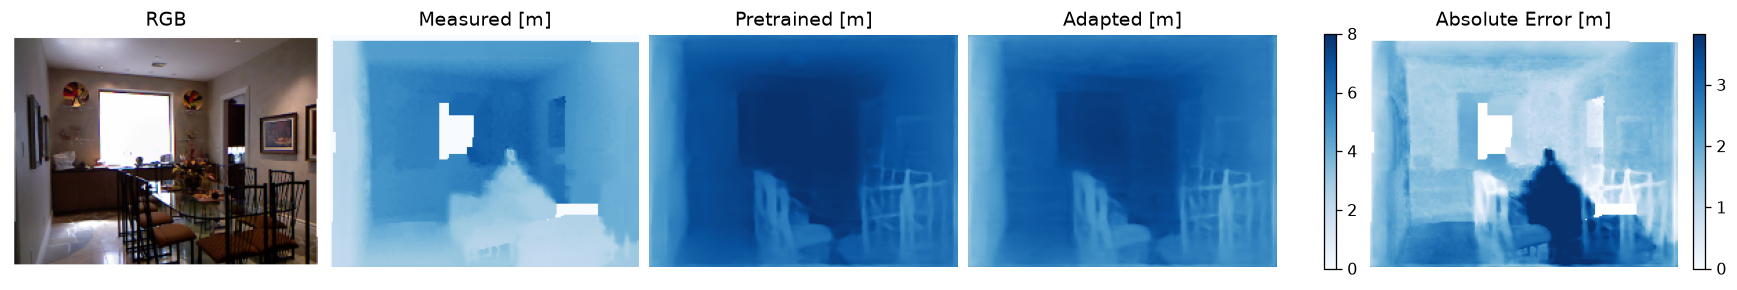

In [7]:
# Final test: run only after choosing learning rates/checkpoints using validation.
with torch.no_grad():
    baseline = copy.deepcopy(model.head).to(DEVICE).eval()
    baseline.load_state_dict(initial_head)
    test_ix = indices["test"]
    pred_before = torch.cat([head_prediction(baseline, i).cpu() for i in test_ix.split(2)])
    pred_after = torch.cat([head_prediction(adapted_head, i).cpu() for i in test_ix.split(2)])
test_depth, test_mask = target[test_ix], valid[test_ix]
before_mae = masked_depth_loss(pred_before, test_depth, test_mask).item()
after_mae = masked_depth_loss(pred_after, test_depth, test_mask).item()
print(f"Held-out test scene | before: {before_mae:.3f} m | after: {after_mae:.3f} m")
if after_mae > before_mae:
    print("Fine-tuning degraded this held-out scene: use this measured outcome in your conclusion.")
j = 0
fig, axes = plt.subplots(1, 5, figsize=(15, 3), constrained_layout=True)
axes[0].imshow(rgb_tensor[test_ix[j]].permute(1, 2, 0).numpy()); axes[0].set_title("RGB")
depth_images = [test_depth[j], pred_before[j], pred_after[j]]
for ax, image, title in zip(axes[1:4], depth_images, ("Measured [m]", "Pretrained [m]", "Adapted [m]")):
    shown = ax.imshow(image, cmap="Blues", vmin=0, vmax=8); ax.set_title(title)
error = (pred_after[j]-test_depth[j]).abs().numpy()
error[~test_mask[j].numpy()] = np.nan
err_plot = axes[4].imshow(error, cmap="Blues", vmin=0, vmax=max(1., float(np.nanpercentile(error, 95))))
axes[4].set_title("Absolute Error [m]")
for ax in axes: ax.axis("off")
fig.colorbar(shown, ax=axes[1:4].tolist(), shrink=.7)
fig.colorbar(err_plot, ax=axes[4], shrink=.7)
fig.savefig(OUT / "metric_depth_comparison.png", bbox_inches="tight")
plt.show()


**Geometry contract:** Pixel coordinates `(u,v)` are zero-based, with `u` right and `v` down. `K` is the camera intrinsic matrix in pixels. Depth `Z` is camera-axis distance in meters, not ray length. `T_BC` maps a homogeneous camera point into the robot-base frame; its translation is in meters.

### Task PAI2-T07 — Complete And Validate Geometry · 9 min
**Do:** Complete C/D: unproject using K, then apply camera-to-base T_BC. Run projection and invalid-depth checks.  
**Produce:** Robot-frame target and independent geometry tests.  
**Check:** Zero, negative, NaN, and infinite depths are rejected.

In [8]:
# Published NYU RGB intrinsics, applied to the aligned 640x480 RGB-D grid.
K_original = np.array([[518.857901, 0., 325.582449],
                       [0., 519.469611, 253.736166], [0., 0., 1.]])
# Original MATLAB toolbox uses 1-based pixels; Python indexes are zero-based.
K_original[0, 2] -= 1.
K_original[1, 2] -= 1.
K = K_original.copy()
K[0] *= WIDTH / 640
K[1] *= HEIGHT / 480
# Resize follows the pixel-center convention used by bilinear image sampling.
K[0, 2] = (K_original[0, 2] + 0.5) * WIDTH/640 - 0.5
K[1, 2] = (K_original[1, 2] + 0.5) * HEIGHT/480 - 0.5
T_BC = np.array([[0., -1., 0., .4], [1., 0., 0., -.1], [0., 0., 1., .2], [0., 0., 0., 1.]])

def unproject(u, v, depth_m, K):
    assert np.isfinite(depth_m) and depth_m > 0, "Depth must be positive meters."
    return np.array([(u - K[0, 2]) / K[0, 0], (v - K[1, 2]) / K[1, 1], 1.0]) * depth_m  # TODO C

def transform_point(point, T):
    assert np.asarray(point).shape == (3,) and T.shape == (4, 4)
    assert np.allclose(T[3], [0, 0, 0, 1])
    assert np.allclose(T[:3, :3].T @ T[:3, :3], np.eye(3), atol=1e-6)
    assert np.isclose(np.linalg.det(T[:3, :3]), 1.0), "A rigid-body rotation cannot be a reflection."
    return T[:3, :3] @ point + T[:3, 3]  # TODO D

# Independent numerical reference: not just a round trip with the same transform.
assert np.allclose(transform_point(np.array([.2, .05, .8]), T_BC), [.35, .1, 1.])
assert np.allclose(unproject(K[0,2], K[1,2], 2., K), [0., 0., 2.])
assert np.allclose(unproject(K[0,2] + K[0,0]/2, K[1,2], 2., K), [1., 0., 2.])
def project_camera_point(point, K):
    if not np.isfinite(point).all() or point[2] <= 0:
        raise ValueError("Projection requires a finite point in front of the camera.")
    homogeneous = K @ point
    return homogeneous[:2] / homogeneous[2]
K_reference = np.array([[100., 0., 50.], [0., 100., 40.], [0., 0., 1.]])
assert np.allclose(project_camera_point(np.array([1., 0., 2.]), K_reference), [100., 40.])
rejected_depths = 0
for invalid_depth in (0., -1., np.nan, np.inf):
    try:
        unproject(20., 30., invalid_depth, K)
    except (AssertionError, ValueError):
        rejected_depths += 1
assert rejected_depths == 4, "Invalid sensor depth must never become a target."
original_uv = np.array([520., 350., 1.])
original_point = unproject(*original_uv[:2], 2.5, K_original)
assert np.allclose(project_camera_point(original_point, K_original), original_uv[:2])
print("Passed: unprojection, independent projection/frame reference, invalid-depth rejection.")


Passed: unprojection, independent projection/frame reference, invalid-depth rejection.


### Task PAI2-T08 — Diagnose Calibration Changes · 6 min
**Do:** Run focal and crop/resize experiments against the fixed measured-depth reference.  
**Produce:** Old-K versus updated-K error graphs.  
**Check:** Update intrinsics when pixels change; do not compensate using test labels.

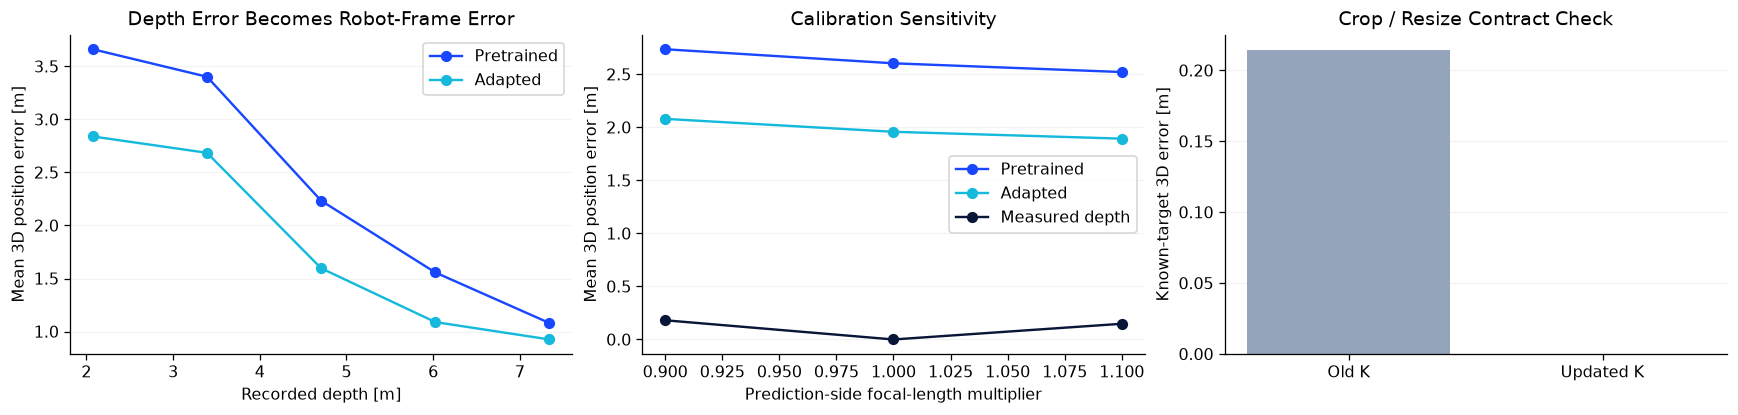

In [9]:
# Sample held-out pixels; original K + recorded metric depth defines the fixed reference.
sample_rng = np.random.default_rng(SEED)
geometry = []
for frame in range(len(test_ix)):
    vv, uu = np.where(test_mask[frame].numpy())
    selected = sample_rng.choice(len(uu), min(150, len(uu)), replace=False)
    for k in selected:
        u, v = int(uu[k]), int(vv[k])
        z_gt = float(test_depth[frame, v, u])
        reference = transform_point(unproject(u, v, z_gt, K), T_BC)
        for scale in (0.9, 1.0, 1.1):
            K_wrong = K.copy()
            K_wrong[0,0] *= scale
            K_wrong[1,1] *= scale
            for name, maps in (("Pretrained", pred_before), ("Adapted", pred_after), ("Measured depth", test_depth)):
                estimate = transform_point(unproject(u, v, float(maps[frame,v,u]), K_wrong), T_BC)
                geometry.append({"model": name, "focal_scale": scale, "depth_m": z_gt,
                                 "error_m": float(np.linalg.norm(estimate-reference))})
bins = np.linspace(.1, 8., 7)
fig, axes = plt.subplots(1, 3, figsize=(15, 3.5), constrained_layout=True)
for name in ("Pretrained", "Adapted"):
    means, centers = [], []
    for lo, hi in zip(bins[:-1], bins[1:]):
        e = [r["error_m"] for r in geometry if r["model"] == name and r["focal_scale"] == 1 and lo <= r["depth_m"] < hi]
        if e: means.append(np.mean(e)); centers.append((lo+hi)/2)
    axes[0].plot(centers, means, "o-", label=name)
for name in ("Pretrained", "Adapted", "Measured depth"):
    scales = [.9, 1., 1.1]
    means = [np.mean([r["error_m"] for r in geometry if r["model"] == name and r["focal_scale"] == s]) for s in scales]
    axes[1].plot(scales, means, "o-", label=name)
axes[0].set(xlabel="Recorded depth [m]", ylabel="Mean 3D position error [m]", title="Depth Error Becomes Robot-Frame Error")
axes[1].set(xlabel="Prediction-side focal-length multiplier", ylabel="Mean 3D position error [m]", title="Calibration Sensitivity")
# Design change: crop the original sensor image, then resize it for the network.
CROP_LEFT, CROP_TOP = 40, 30  # Change these, rerun, and inspect the third plot.
CROP_WIDTH, CROP_HEIGHT = 560, 400
sx, sy = WIDTH / CROP_WIDTH, HEIGHT / CROP_HEIGHT
crop_resize = np.array([[sx, 0., sx*(.5-CROP_LEFT)-.5],
                        [0., sy, sy*(.5-CROP_TOP)-.5], [0., 0., 1.]])
K_cropped = crop_resize @ K_original
cropped_uv = crop_resize @ original_uv
assert 0 <= cropped_uv[0] < WIDTH and 0 <= cropped_uv[1] < HEIGHT
corrected = unproject(*cropped_uv[:2], 2.5, K_cropped)
stale_K = unproject(*cropped_uv[:2], 2.5, K)
crop_errors = [np.linalg.norm(stale_K-original_point), np.linalg.norm(corrected-original_point)]
assert crop_errors[1] < 1e-9 and crop_errors[0] > .001
axes[2].bar(["Old K", "Updated K"], crop_errors, color=[SILVER, BLUE])
axes[2].set(title="Crop / Resize Contract Check", ylabel="Known-target 3D error [m]")
for ax in axes[:2]: ax.legend()
for ax in axes: ax.grid(alpha=.15, axis="y")
fig.savefig(OUT / "geometry_and_calibration.png", bbox_inches="tight")
plt.show()
# Same wrong rigid transform on both points would preserve Euclidean distance;
# this experiment perturbs prediction-side K, against an unchanged reference.
(OUT / "geometry_metrics.json").write_text(json.dumps(geometry, indent=2))


### Task PAI2-T09 — Inspect The 3D Reconstruction · 2 min
**Do:** Run the paired 3D view and compare measured with adapted targets.  
**Produce:** Two robot-frame point-cloud views.  
**Check:** Both plots use the same units and axis limits.

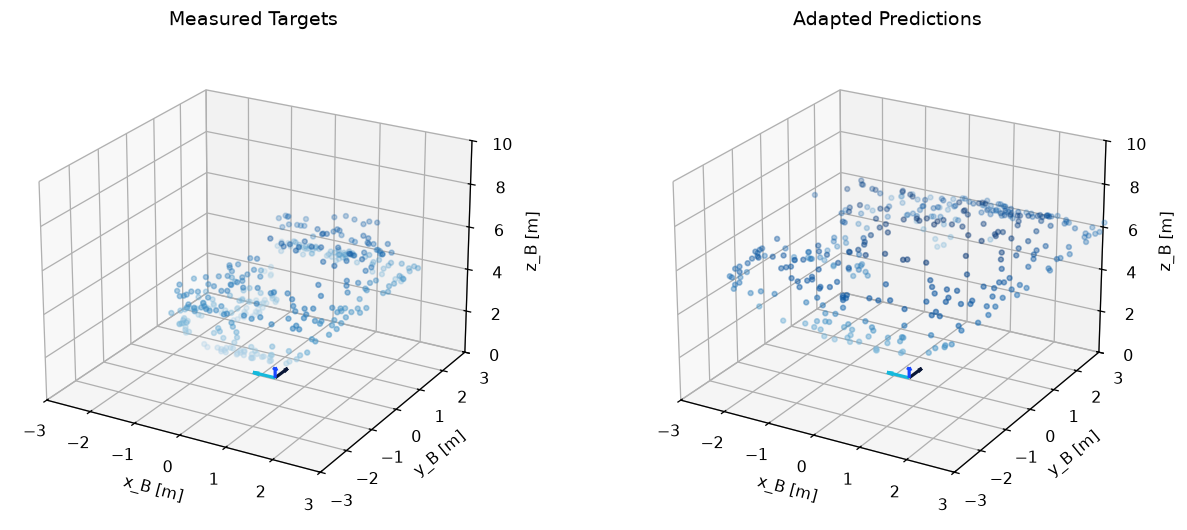

In [10]:
# View how depth predictions move reconstructed targets in the robot-base frame.
j = 0
vv, uu = np.where(test_mask[j].numpy())
selected = np.random.default_rng(SEED).choice(len(uu), min(350, len(uu)), replace=False)
fig = plt.figure(figsize=(11, 4.5), constrained_layout=True)
for panel, (name, depth_map) in enumerate((("Measured Targets", test_depth[j]),
                                          ("Adapted Predictions", pred_after[j])), 1):
    ax = fig.add_subplot(1, 2, panel, projection="3d")
    points = np.array([transform_point(unproject(int(uu[k]), int(vv[k]),
                           float(depth_map[vv[k], uu[k]]), K), T_BC) for k in selected])
    ax.scatter(points[:,0], points[:,1], points[:,2], c=points[:,2], cmap="Blues",
               vmin=0, vmax=8, s=9, alpha=.75)
    origin = T_BC[:3,3]
    for axis, color in zip(range(3), (NAVY, CYAN, BLUE)):
        direction = T_BC[:3,axis] * .5
        ax.quiver(*origin, *direction, color=color, linewidth=2)
    ax.set(xlabel="x_B [m]", ylabel="y_B [m]", zlabel="z_B [m]", title=name,
           xlim=(-3, 3), ylim=(-3, 3), zlim=(0, 10))
    ax.view_init(elev=23, azim=-60)
fig.savefig(OUT / "robot_frame_3d_targets.png", bbox_inches="tight")
plt.show()


**State versus observation:** The image and measured depth are observations; predicted depth is an estimate. A belief describes uncertainty over state. This deterministic stage does not implement a Bayesian belief filter. Its current Cartesian position and accepted target define the control error.

### Task PAI2-T10 — Convert A Target Into An Action · 7 min
**Do:** Complete E: bounded Cartesian velocity after validity, freshness, and workspace checks. Run the fault cases.  
**Produce:** Stage motion and accept/reject evidence.  
**Check:** Rejected targets cause zero motion; tracking an estimate does not prove perception accuracy.

Target pixel: (112, 84) | Predicted depth: 7.653 m
Accepted base-frame target [m]: [ 0.574 -0.154  7.853]
Interface tests: {'invalid depth': 'reject_depth', 'stale observation': 'reject_stale', 'unreachable target': 'reject_workspace', 'nonfinite target': 'reject_depth'}
Tracking the predicted target: 0.001 m; error against measured-depth target: 1.134 m


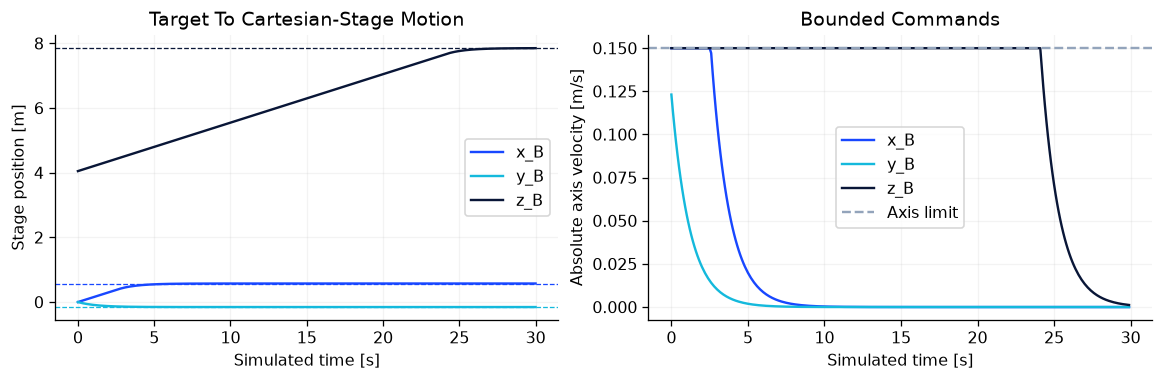

In [11]:
WORKSPACE_LOW = np.array([-3., -3., .1])
WORKSPACE_HIGH = np.array([3., 3., 8.])
SPEED_LIMIT = .15  # Per-axis stage velocity limit [m/s].
MAX_OBSERVATION_AGE = .25  # Allowed age in the injected interface test [s].

def stage_command(current, target, depth_valid, observed_at_s, now_s,
                  kp=.8, speed_limit=SPEED_LIMIT):
    current, target = np.asarray(current, dtype=float), np.asarray(target, dtype=float)
    hold = np.zeros(3, dtype=float)
    if current.shape != (3,) or target.shape != (3,):
        return hold, "reject_shape"
    if not depth_valid or not np.isfinite(target).all():
        return hold, "reject_depth"
    if not np.isfinite(current).all() or np.any(current < WORKSPACE_LOW) or np.any(current > WORKSPACE_HIGH):
        return hold, "reject_state"
    if not np.isfinite([observed_at_s, now_s]).all() or not 0 <= now_s-observed_at_s <= MAX_OBSERVATION_AGE:
        return hold, "reject_stale"
    if np.any(target < WORKSPACE_LOW) or np.any(target > WORKSPACE_HIGH):
        return hold, "reject_workspace"
    velocity = np.clip(kp * (target - current), -speed_limit, speed_limit)  # TODO E
    assert velocity.shape == (3,) and np.isfinite(velocity).all()
    assert np.all(np.abs(velocity) <= speed_limit + 1e-9), "Bound every commanded axis."
    return velocity, "move"

# Choose an actual predicted-depth target nearest the image center that is in the
# declared stage workspace. The reference depth is not used as an action target.
vv, uu = np.where(test_mask[0].numpy())
nearest = np.argsort((uu-WIDTH/2)**2 + (vv-HEIGHT/2)**2)
chosen = None
for pixel_index in nearest:
    u, v = int(uu[pixel_index]), int(vv[pixel_index])
    predicted_z = float(pred_after[0, v, u])
    if not np.isfinite(predicted_z) or predicted_z <= 0:
        continue
    point_B = transform_point(unproject(u, v, predicted_z, K), T_BC)
    if np.all(point_B >= WORKSPACE_LOW) and np.all(point_B <= WORKSPACE_HIGH):
        chosen = (u, v, predicted_z, point_B)
        break
assert chosen is not None, "No valid target in this workspace: hold and choose another observation."
target_B = chosen[3]
current = (WORKSPACE_LOW + WORKSPACE_HIGH) / 2
command, status = stage_command(current, target_B, True, .95, 1.)
assert status == "move"
outside = target_B.copy(); outside[0] = WORKSPACE_HIGH[0] + 1.
cases = {
    "invalid depth": (target_B, False, .95, 1., "reject_depth"),
    "stale observation": (target_B, True, 0., 1., "reject_stale"),
    "unreachable target": (outside, True, .95, 1., "reject_workspace"),
    "nonfinite target": (np.array([np.nan, 0., 1.]), True, .95, 1., "reject_depth"),
}
checks = {}
for label, (target, depth_ok, observed_at, now, expected) in cases.items():
    original = target.copy()
    velocity_test, result = stage_command(current, target, depth_ok, observed_at, now)
    assert result == expected and np.array_equal(velocity_test, np.zeros(3))
    assert np.array_equal(target, original, equal_nan=True), "Do not clamp or mutate the target."
    checks[label] = result
print("Target pixel:", chosen[:2], "| Predicted depth:", round(chosen[2], 3), "m")
print("Accepted base-frame target [m]:", np.round(target_B, 3))
print("Interface tests:", checks)

# Known Cartesian-stage kinematics: position[k+1] = position[k] + velocity[k]*dt.
# Fresh timestamps are injected at each simulated control step; no NYU sequence
# is treated as a synchronized live measurement of this stage.
dt = .1
stage_positions, stage_velocities = [current.copy()], []
for k in range(300):
    now = k*dt
    velocity_k, status_k = stage_command(current, target_B, True, now, now)
    assert status_k == "move"
    current = current + velocity_k*dt
    assert np.all(current >= WORKSPACE_LOW) and np.all(current <= WORKSPACE_HIGH)
    stage_positions.append(current.copy()); stage_velocities.append(velocity_k.copy())
positions, velocities = np.array(stage_positions), np.array(stage_velocities)
assert np.linalg.norm(positions[-1]-target_B) < .01
# Offline audit only: measured test depth is NOT supplied to the controller.
measured_reference_B = transform_point(unproject(chosen[0], chosen[1],
                              float(test_depth[0, chosen[1], chosen[0]]), K), T_BC)
tracking_error = float(np.linalg.norm(positions[-1]-target_B))
reference_error = float(np.linalg.norm(positions[-1]-measured_reference_B))
print(f"Tracking the predicted target: {tracking_error:.3f} m; "
      f"error against measured-depth target: {reference_error:.3f} m")
fig, axes = plt.subplots(1, 2, figsize=(10, 3.2), constrained_layout=True)
for axis, color in enumerate((BLUE, CYAN, NAVY)):
    axes[0].plot(np.arange(len(positions))*dt, positions[:,axis], color=color, label="xyz"[axis]+"_B")
    axes[0].axhline(target_B[axis], color=color, linestyle="--", linewidth=.8)
    axes[1].plot(np.arange(len(velocities))*dt, np.abs(velocities[:,axis]), color=color, label="xyz"[axis]+"_B")
axes[1].axhline(SPEED_LIMIT, color=SILVER, linestyle="--", label="Axis limit")
axes[0].set(title="Target To Cartesian-Stage Motion", xlabel="Simulated time [s]", ylabel="Stage position [m]")
axes[1].set(title="Bounded Commands", xlabel="Simulated time [s]", ylabel="Absolute axis velocity [m/s]")
for ax in axes: ax.legend(); ax.grid(alpha=.15)
fig.savefig(OUT / "cartesian_stage_commands.png", bbox_inches="tight")
plt.show()
stage_report = {"stage": "teaching three-axis Cartesian stage", "frame": "B", "target_m": target_B.tolist(),
                "workspace_low_m": WORKSPACE_LOW.tolist(), "workspace_high_m": WORKSPACE_HIGH.tolist(),
                "axis_speed_limit_m_s": SPEED_LIMIT, "injected_timestamp_tests": checks,
                "measured_reference_target_m": measured_reference_B.tolist(),
                "predicted_target_tracking_error_m": tracking_error,
                "measured_reference_target_error_m": reference_error,
                "reference_depth_used_for_control": False}
(OUT / "stage_interface_checks.json").write_text(json.dumps(stage_report, indent=2))


### Task PAI2-T11 — Save And Explain · 4 min
**Do:** Export and write one sentence each about validation, test-depth error, and geometry-to-action limits.  
**Produce:** Checkpoint, manifests, plots, and conclusions.  
**Check:** Reload matches; this teaching Cartesian stage is not general robot IK or safety certification.

In [12]:
#@title Provided code — run this cell
# Save real trained weights, source revisions, evaluation and experiment settings.
checkpoint = {"model_id": MODEL_ID, "model_revision": MODEL_REV, "data_revision": DATA_REV,
              "head_state_dict": {k:v.detach().cpu() for k,v in best_run["state"].items()},
              "resolution_hw": [HEIGHT, WIDTH], "K": K.tolist(), "T_BC": T_BC.tolist(),
              "learning_rate": best_run["lr"], "train_steps": TRAIN_STEPS,
              "seed": SEED, "validation_mae_m": best_run["validation_mae"],
              "test_mae_before_m": before_mae, "test_mae_after_m": after_mae}
torch.save(checkpoint, OUT / "metric_depth_adapted_head.pt")
reloaded = torch.load(OUT / "metric_depth_adapted_head.pt", map_location="cpu", weights_only=True)
reloaded_head = copy.deepcopy(model.head).to(DEVICE).eval()
reloaded_head.load_state_dict(reloaded["head_state_dict"], strict=True)
with torch.no_grad():
    assert torch.allclose(head_prediction(reloaded_head, test_ix[:1]),
                          head_prediction(adapted_head, test_ix[:1]), atol=1e-6)
(OUT / "training_history.json").write_text(json.dumps(
    [{k:v for k,v in run.items() if k != "state"} for run in runs], indent=2))
print("Saved:", ", ".join(p.name for p in OUT.iterdir()))


Saved: cartesian_stage_commands.png, data_manifest.json, geometry_and_calibration.png, geometry_metrics.json, metric_depth_adapted_head.pt, metric_depth_comparison.png, robot_frame_3d_targets.png, stage_interface_checks.json, training_curves.png, training_history.json


**Reference interpretation:** Select by validation MAE, not test MAE. In the recorded reference run, learning rate `1e-5` was selected and test MAE changed from `2.405 m` to `1.806 m`. The measured-depth calibration control has zero reconstruction error at the original intrinsics. Your rerun can differ; report its measured values.

<details><summary>Sources And Reproducibility</summary>

- Barak Or, *Physical AI Essentials*, Lesson 2: Camera Geometry; Coordinate Frames And Rigid Transformations.
- [Silberman et al., NYU Depth V2, ECCV 2012](https://cs.nyu.edu/~fergus/datasets/nyu_depth_v2.html).
- [Public HDF5 mirror and its dataset card](https://huggingface.co/datasets/sayakpaul/nyu_depth_v2), pinned to `50579a0b591445f91bf7269b28611ad1cc6a05d2`. The mirror lists Apache-2.0; preserve original dataset attribution and applicable source terms.
- [Depth Anything V2 metric indoor Small](https://huggingface.co/depth-anything/Depth-Anything-V2-Metric-Indoor-Small-hf), pinned to `8078d68a9c75a972131914f6afd0c1723be0da7f`; [official metric-depth implementation](https://github.com/DepthAnything/Depth-Anything-V2/tree/main/metric_depth).
- [Original NYU camera calibration toolbox](https://cs.nyu.edu/~fergus/datasets/toolbox_nyu_depth_v2.zip), `camera_params.m` and `depth_plane2depth_world.m`: convert its 1-based principal point to zero-based pixels before resizing. Approximate Kinect intrinsics are used for this teaching reconstruction; `T_BC` is explicitly supplied, not measured from NYU.
- Backbone/neck inference uses recorded RGB only. The head is genuinely updated by gradient descent. No synthetic RGB-D substitute, test-image scale alignment, or reference-output substitution is used.

</details>
